<span style="font-family:monospace;letter-spacing:.14em;color:#857259">BANA · MODULE 2 · EXPLORING AND VISUALISING DATA</span>

# Session 2: Describing numbers: centre, spread and shape

**Dataset:** EV purchase intention (Kaggle Playground Series S6E9, a *synthetic* dataset). You work with a 10,000-row seeded sample, `ev_m2_sample.csv`.
**Time:** 60 minutes. **Course outcomes:** CO2 (and CO3 for Session 5).

| Block | Min | What you do |
|---|---|---|
| Hook | 5 | Anscombe's quartet: same numbers, different data |
| Concept | 10 | Mean vs median, spread, skew (instructor) |
| Guided lab | 30 | Profile age, income, commute; compare buyers and non-buyers |
| Team task | 10 | Defend one 'typical customer' number |
| Exit ticket | 5 | Three quick checks |

**By the end of this session you can:**
- choose between mean and median and defend the choice
- read a histogram for centre, spread and shape
- spot a suspicious spike
- compare a number across groups

**New commands this session (max 5):** `describe()`, `mean()` / `median()`, `sns.histplot`, `groupby().mean()`, `sort_values()`

**AI-use (AMBER protocol).** You may use an AI tool to look up *syntax*. The reasoning and interpretation must be your own: you will defend them in the viva.

## Facilitator notes: Session 2
**Question for the room:** *Is the average a useful picture of our customers?*

**Run of show**
1. **Hook (5):** run the Anscombe cell. Four datasets, identical means, spreads and correlation, four different pictures (Anscombe, 1973).
2. **Concept (10):** mean = balance point, median = middle person; spread (std, IQR); skew; when they differ and why a manager cares.
3. **Lab (30):** Parts B to E.
4. **Team task (10):** each pair picks one 'typical customer' number and defends it in 30 seconds.

**What the data actually shows (sample of 10,000)**
- **Age** is roughly flat across 25 to 69, mean about 47; no spike. (If students set Age bins to 40 they will see fake spikes: whole-year ages fall unevenly into bins. Use this to teach that bin width is a choice.)
- **Income** looks like a bell *plus a spike at exactly 30,000*: **8.8%** of buyers earn exactly 30,000. That is a floor (a minimum applied to the data), not a coincidence.
- **Commute** has a spike at exactly 5 km: **21.7%** of rows. Mean 32.0 km and median 33.5 km are close, **but only 17.7% of people commute within 5 km of the 'average' 32 km**. The average person is rare.
- Buyers earn far more (about 99k vs 82k) and commute somewhat less (about 29 vs 33 km); age is the same (47).

**Trap:** students conclude 'mean and median are about equal so the data is symmetric and fine'. Push back: equal centre does not mean no problem; the histogram shows the floor.

In [1]:
# -- Setup: run once ------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
warnings.filterwarnings("ignore")

# House style: Nikhil D Jonathan design system (sand ground, terracotta / lagoon / ochre data colours)
C = {"lagoon": "#25707B", "terracotta": "#B5562F", "ochre": "#E0A231", "moss": "#3F6F4B",
     "earth": "#665643", "ink": "#221B15", "sand": "#F8F3EA", "card": "#FFFDF9", "line": "#E3D6C1"}
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": C["sand"], "axes.facecolor": C["card"], "axes.edgecolor": "#CDBCA3",
    "grid.color": C["line"], "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "xtick.color": "#4A3E31", "ytick.color": "#4A3E31", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left"})
PCT = PercentFormatter(1, decimals=0)                              # axis labels as percentages
SEQ = sns.light_palette(C["terracotta"], as_cmap=True)   # one-hue sequential map for heatmaps

# -- Load the data (Colab: upload ev_m2_sample.csv to the Files pane, or run the upload below)
FILE = "ev_m2_sample.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Choose ev_m2_sample.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Put ev_m2_sample.csv in the same folder as this notebook.")
raw = pd.read_csv(FILE)
df = raw.copy()
print("Loaded", df.shape[0], "rows x", df.shape[1], "columns")

Loaded 10000 rows x 15 columns


## Part A. Hook: same numbers, different data (5 min)

         x_mean  y_mean  y_std
dataset                       
I           9.0     7.5   2.03
II          9.0     7.5   2.03
III         9.0     7.5   2.03
IV          9.0     7.5   2.03
Correlation x-y: {'I': np.float64(0.816), 'II': np.float64(0.816), 'III': np.float64(0.816), 'IV': np.float64(0.817)}


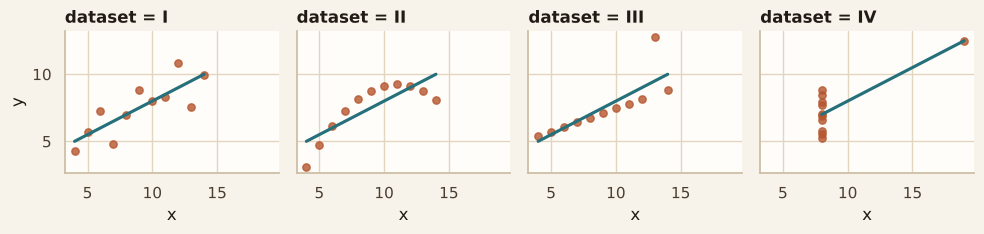

In [2]:
an = sns.load_dataset("anscombe")      # needs internet (Colab is fine)
print(an.groupby("dataset").agg(x_mean=("x", "mean"), y_mean=("y", "mean"), y_std=("y", "std")).round(2))
print("Correlation x-y:", {k: round(g["x"].corr(g["y"]), 3) for k, g in an.groupby("dataset")})
sns.lmplot(data=an, x="x", y="y", col="dataset", col_wrap=4, height=2.5, ci=None,
           scatter_kws={"color": C["terracotta"], "s": 28}, line_kws={"color": C["lagoon"]});

**Question:** the table says the four datasets are the same. What does the picture say? Write one sentence.

> _write here_

## Part B. Setup for this session
Run the setup cell above, then rebuild the derived columns.

In [3]:
def add_derived(d):
    """The four derived columns built in Session 1 (pre-written so every notebook stands alone)."""
    d = d.copy()
    d["buy"] = (d["Will_Buy_EV"] == "Yes").astype(int)
    d["age_band"] = pd.cut(d["Age"], bins=[24, 34, 44, 54, 69], labels=["25-34", "35-44", "45-54", "55-69"])
    d["income_band"] = pd.qcut(d["Annual_Income_USD"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
    d["charger_total"] = d["Charging_Stations_Near_Home"] + d["Charging_Stations_Near_Work"]
    return d

In [4]:
df = add_derived(raw)
num_cols = ['Age', 'Annual_Income_USD', 'Daily_Commute_km']
df[num_cols].head()

,Age,Annual_Income_USD,Daily_Commute_km
0,34,95772.0,22.0
1,53,106533.0,24.2
2,63,73220.0,17.6
3,69,30000.0,5.0
4,52,76983.0,50.8


## Part C. Describe the numbers (10 min)
**Predict first:** which of the three columns will have the biggest gap between mean and median? Write a guess.

In [5]:
df[num_cols].describe().round(1)

,Age,Annual_Income_USD,Daily_Commute_km
count,10000.0,9512.0,9835.0
mean,47.0,84806.8,32.0
std,12.9,28952.1,18.8
min,25.0,30000.0,5.0
25%,36.0,67413.2,16.8
50%,47.0,84835.5,33.5
75%,58.0,102959.0,47.2
max,69.0,178827.0,96.0


In [6]:
summary = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "std": df[num_cols].std(),
}).round(1)
summary["mean_minus_median"] = (summary["mean"] - summary["median"]).round(1)
summary

,mean,median,std,mean_minus_median
Age,47.0,47.0,12.9,0.0
Annual_Income_USD,84806.8,84835.5,28952.1,-28.7
Daily_Commute_km,32.0,33.5,18.8,-1.5


**YOUR ANSWER:** Was your guess right? Which column has the biggest gap, and in which direction does the tail pull the mean?

> _write here_

## Part D. Look at the shape (10 min)
**Predict first:** sketch what you expect each histogram to look like (bell? flat? skewed?). Then run.

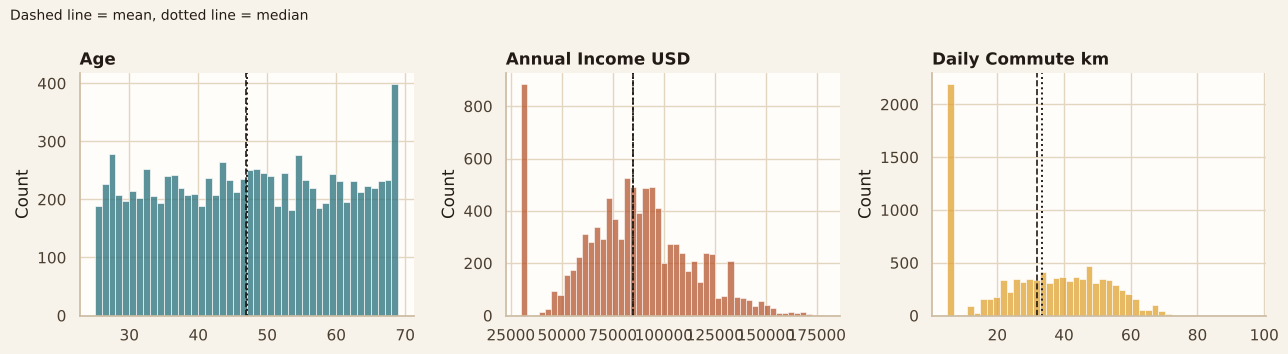

In [7]:
widths = {"Age": 1, "Annual_Income_USD": 3000, "Daily_Commute_km": 2}      # bin width in the column's own units
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, colour in zip(axes, num_cols, [C["lagoon"], C["terracotta"], C["ochre"]]):
    sns.histplot(df[col], binwidth=widths[col], color=colour, ax=ax)
    ax.axvline(df[col].mean(), color=C["ink"], ls="--", lw=1.2)     # dashed = mean
    ax.axvline(df[col].median(), color=C["ink"], ls=":", lw=1.4)    # dotted = median
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("")
fig.suptitle("Dashed line = mean, dotted line = median", x=0.01, ha="left", fontsize=10)
plt.tight_layout()

**YOUR ANSWER:** Two of the three histograms have something odd at one end. Which, and what do you think it means?

> _write here_

In [8]:
print(f"Share of rows with income exactly 30,000: {(df['Annual_Income_USD'] == 30000).mean():.1%}")
print(f"Share of rows with commute exactly 5 km:      {(df['Daily_Commute_km'] == 5).mean():.1%}")
avg = df["Daily_Commute_km"].mean()
near = ((df["Daily_Commute_km"] - avg).abs() <= 5).mean()
print(f"Share of people within 5 km of the 'average' commute of {avg:.0f} km: {near:.1%}")

Share of rows with income exactly 30,000: 8.8%
Share of rows with commute exactly 5 km:      21.7%
Share of people within 5 km of the 'average' commute of 32 km: 17.7%


**Expected:** income spike 8.8%, commute spike 21.7%, and only 17.7% of people live near the 'average' commute. Teaching line: *the average describes almost nobody here.*

## Part E. Compare buyers and non-buyers (10 min)

In [9]:
by_target = df.groupby("Will_Buy_EV")[num_cols].mean().round(0)
by_target

,Age,Annual_Income_USD,Daily_Commute_km
Will_Buy_EV,,,
No,47.0,81575.0,33.0
Yes,47.0,99355.0,29.0


In [10]:
# Which customer group has the highest Yes rate?  (sort_values puts the biggest first)
df.groupby("City_Type")["buy"].mean().sort_values(ascending=False).round(3)

City_Type
Rural       0.216
Suburban    0.185
Urban       0.164
Name: buy, dtype: float64

**YOUR ANSWER:** Which of age, income and commute separates buyers from non-buyers most? Which barely matters? (Look at the gap between the two rows.)

> _write here_

**Expected:** income (buyers ≈ 99k vs non-buyers ≈ 82k) separates most; commute differs somewhat (buyers about 29 km vs 33 km); age is the same (47 vs 47). Rural has the highest Yes rate (21.6%), then Suburban (18.5%), then Urban (16.4%). *Do not explain the city pattern yet; Session 4 shows why.*

## Team task: defend one 'typical customer' number (10 min)
A manager asks: *What does a typical EV prospect look like?* In your pair, pick **one** of income, age or commute, choose **mean or median**, and write a one-sentence answer a manager can use. Then add one sentence on what the number hides.

In [11]:
# Save your numeric profile (this is your Session 2 output)
profile = summary.copy()
profile.to_csv("numeric_profile.csv")
profile

,mean,median,std,mean_minus_median
Age,47.0,47.0,12.9,0.0
Annual_Income_USD,84806.8,84835.5,28952.1,-28.7
Daily_Commute_km,32.0,33.5,18.8,-1.5


## Exit ticket (5 min)
1. When would you report the median instead of the mean?
2. A histogram shows a tall bar at exactly one value. Name one real-world reason this might happen.
3. Age is the same for buyers and non-buyers. Does that prove age does not matter in real life? Why not?

**Answers:** (1) skewed data or extreme values; (2) a floor, a cap, a default value, or a data-entry rule; (3) no: this is a synthetic file and one comparison of means; a real sample could differ, and the mean can hide pattern within age groups.

**Viva prompt (AMBER):** "Why did you choose the mean (or the median) for your typical customer number? What would change your mind?"

### References (facilitator only)
Anscombe, F. J. (1973). Graphs in statistical analysis. *The American Statistician*, 27(1), 17-21.
Matejka, J., & Fitzmaurice, G. (2017). Same stats, different graphs. *Proceedings of CHI 2017*. ACM.
Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
GAISE College Report ASA Revision Committee (2016). *Guidelines for Assessment and Instruction in Statistics Education: College Report 2016*. American Statistical Association.